In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout, Reshape, Permute
import time #helper libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-12-11 20:14:41.856684: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-11 20:14:42.665156: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-11 20:14:43.426036: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-11 20:14:43.426096: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-11 20:14:43.471883: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)


In [3]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [4]:
df

,timestamp,symbol,open,high,low,close,volume,sma_10,sma_50,ema_20,...,sum_of_scores,avg_of_scores,normalized_avg,max_of_scores,min_of_scores,normalized_min,normalized_max,avg_score_of_normalized_min,avg_score_of_normalized_max,avg_score_of_normalized_avg
0,2023-01-03 09:00:00,TSLA,120.02,121.23,115.94,118.52,1306706,118.5200,118.5200,118.520000,...,"[-7, 2, 7, 1, -2, 5, 2, 0, 1, 5]","[-3.5, 1.0, 3.5, 0.5, -1.0, 2.5, 1.0, 0.0, 0.5...","[-0.7, 0.2, 0.7, 0.1, -0.2, 0.5, 0.2, 0.0, 0.1...","[-3, 1, 5, 4, 0, 5, 3, 1, 1, 3]","[-4, 1, 2, -3, -2, 0, -1, -1, 0, 2]","[-0.8, 0.2, 0.4, -0.6, -0.4, 0.0, -0.2, -0.2, ...","[-0.6, 0.2, 1.0, 0.8, 0.0, 1.0, 0.6, 0.2, 0.2,...",-0.12,0.40,0.140000
1,2023-01-03 10:00:00,TSLA,118.53,120.50,118.20,120.38,568635,119.4500,119.4500,118.697143,...,"[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2.0, 5.0, 0.0, 3.0, -1.0, 4.0, 0.0, -2.0, -2....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[2, 5, 0, 3, -1, 4, 0, -2, -2, 4]","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....","[0.4, 1.0, 0.0, 0.6, -0.2, 0.8, 0.0, -0.4, -0....",0.26,0.26,0.260000
2,2023-01-03 11:00:00,TSLA,120.28,120.50,117.95,118.61,547403,119.1700,119.1700,118.688844,...,"[-18, 14, 10, 10, 2, 11, -2, 15, -7, -7]","[-3.0, 2.3333333333333335, 1.6666666666666667,...","[-0.6, 0.4666666666666667, 0.33333333333333337...","[-2, 5, 4, 5, 1, 5, 3, 6, 1, 2]","[-5, 0, 0, -2, -1, -1, -4, 0, -5, -5]","[-1.0, 0.0, 0.0, -0.4, -0.2, -0.2, -0.8, 0.0, ...","[-0.4, 1.0, 0.8, 1.0, 0.2, 1.0, 0.6, 1.2, 0.2,...",-0.46,0.60,0.093333
3,2023-01-03 12:00:00,TSLA,118.63,118.99,116.61,118.28,1529445,118.9475,118.9475,118.649906,...,"[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4.0, 0.0, 3.0, -1.0, -5.0, 0.0, 0.0, -2.0, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-4, 0, 3, -1, -5, 0, 0, -2, -4, 1]","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...","[-0.8, 0.0, 0.6, -0.2, -1.0, 0.0, 0.0, -0.4, -...",-0.24,-0.24,-0.240000
4,2023-01-03 13:00:00,TSLA,118.32,121.90,116.61,118.93,2886437,118.9440,118.9440,118.676582,...,"[-20, 2, 19, 16, 6, 16, 4, 5, -2, 9]","[-2.5, 0.25, 2.375, 2.0, 0.75, 2.0, 0.5, 0.625...","[-0.5, 0.05, 0.475, 0.4, 0.15, 0.4, 0.1, 0.125...","[0, 2, 5, 4, 5, 5, 3, 3, 2, 5]","[-5, -4, 0, -4, -5, -2, -2, -3, -5, -1]","[-1.0, -0.8, 0.0, -0.8, -1.0, -0.4, -0.4, -0.6...","[0.0, 0.4, 1.0, 0.8, 1.0, 1.0, 0.6, 0.6, 0.4, ...",-0.62,0.68,0.137500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,2023-12-08 13:00:00,TSLA,242.19,243.37,239.75,240.40,1406899,242.3970,241.1094,241.760952,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1033,2023-12-08 14:00:00,TSLA,240.46,243.65,239.27,242.40,15237079,242.3730,241.2916,241.821814,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1034,2023-12-08 15:00:00,TSLA,242.40,245.23,242.40,245.19,22432349,242.6320,241.5218,242.142593,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.00,0.00,0.000000
1035,2023-12-08 16:00:00,TSLA,245.19,245.27,241.67,241.97,15853691,242.5470,241.5982,242.126156,...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 0,

# LSTM

## close price only

In [5]:
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [6]:
np.random.seed(5)


In [7]:
# take close price column[5]
all_y = df["close"].values
dataset=all_y.reshape(-1, 1)


In [8]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [9]:
# split into train and test sets, 50% test data, 50% training data
train_size = int(len(dataset) * 0.7)
test_size = len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

In [10]:
look_back = 30
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [11]:

# reshape input to be [samples, time steps, features]
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1))
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

# create and fit the LSTM network, optimizer=adam, 25 neurons, dropout 0.1
model = Sequential()
model.add(LSTM(25, input_shape=(look_back, 1)))
model.add(Dropout(0.1))
model.add(Dense(1))
model.compile(loss='mse', optimizer='adam')
model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=1)

2025-12-11 20:15:18.072717: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Epoch 1/1000
3/3 [==============================] - 2s 13ms/step - loss: 0.3034
Epoch 2/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.2086
Epoch 3/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.1332
Epoch 4/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0779
Epoch 5/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0383
Epoch 6/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0179
Epoch 7/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0109
Epoch 8/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0143
Epoch 9/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0196
Epoch 10/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0185
Epoch 11/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0150
Epoch 12/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0115
Epoch 13/1000
3/3 [======================

3/3 [==============================] - 0s 10ms/step - loss: 0.0032
Epoch 203/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0030
Epoch 204/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0031
Epoch 205/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0034
Epoch 206/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0032
Epoch 207/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0033
Epoch 208/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0032
Epoch 209/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0029
Epoch 210/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0031
Epoch 211/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0029
Epoch 212/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0030
Epoch 213/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0032
Epoch 214/1000
3/3 [===========

3/3 [==============================] - 0s 12ms/step - loss: 0.0028
Epoch 303/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0027
Epoch 304/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0028
Epoch 305/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0026
Epoch 306/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0027
Epoch 307/1000
3/3 [==============================] - 0s 12ms/step - loss: 0.0029
Epoch 308/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0027
Epoch 309/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0028
Epoch 310/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0028
Epoch 311/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0026
Epoch 312/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0026
Epoch 313/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0025
Epoch 314/1000
3/3 [===========

3/3 [==============================] - 0s 9ms/step - loss: 0.0022
Epoch 503/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0026
Epoch 504/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0024
Epoch 505/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0022
Epoch 506/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0020
Epoch 507/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0022
Epoch 508/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0023
Epoch 509/1000
3/3 [==============================] - 0s 12ms/step - loss: 0.0023
Epoch 510/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0021
Epoch 511/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0024
Epoch 512/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0021
Epoch 513/1000
3/3 [==============================] - 0s 12ms/step - loss: 0.0021
Epoch 514/1000
3/3 [===============

3/3 [==============================] - 0s 11ms/step - loss: 0.0019
Epoch 703/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0019
Epoch 704/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0018
Epoch 705/1000
3/3 [==============================] - 0s 11ms/step - loss: 0.0016
Epoch 706/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0018
Epoch 707/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0019
Epoch 708/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0019
Epoch 709/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0018
Epoch 710/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0017
Epoch 711/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0018
Epoch 712/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0016
Epoch 713/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0017
Epoch 714/1000
3/3 [=================

3/3 [==============================] - 0s 9ms/step - loss: 0.0015
Epoch 903/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0015
Epoch 904/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0015
Epoch 905/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0016
Epoch 906/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0015
Epoch 907/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0015
Epoch 908/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0016
Epoch 909/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0015
Epoch 910/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0016
Epoch 911/1000
3/3 [==============================] - 0s 10ms/step - loss: 0.0015
Epoch 912/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0014
Epoch 913/1000
3/3 [==============================] - 0s 9ms/step - loss: 0.0016
Epoch 914/1000
3/3 [====================

9/9 [==============================] - 0s 2ms/step
Train Score: 4.38 RMSE
Test Score: 4.46 RMSE


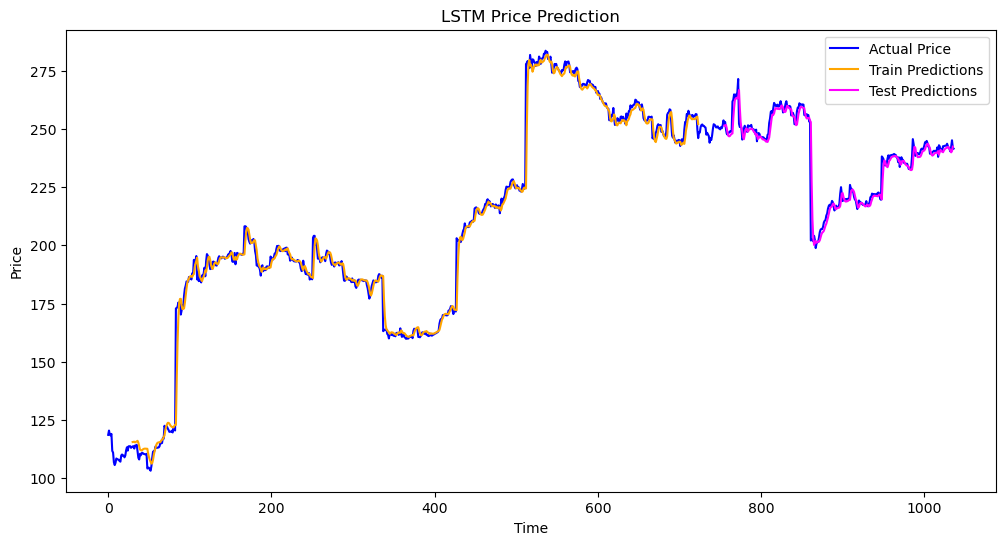

testPrices:
testPredictions:
[[251.52014]
 [251.35516]
 [251.74184]
 [250.37912]
 [248.42464]
 [247.05684]
 [246.88933]
 [247.0968 ]
 [247.6281 ]
 [247.96652]
 [248.13191]
 [254.62094]
 [259.2478 ]
 [262.63153]
 [263.1508 ]
 [263.47546]
 [263.10504]
 [263.5605 ]
 [266.78485]
 [259.10092]
 [253.06358]
 [250.20308]
 [249.10608]
 [246.5818 ]
 [245.65811]
 [247.54898]
 [249.62459]
 [250.36424]
 [249.84595]
 [248.89638]
 [249.56653]
 [249.95071]
 [249.98209]
 [250.01904]
 [250.24991]
 [249.58702]
 [248.97997]
 [248.66096]
 [248.00699]
 [247.22646]
 [247.76147]
 [245.77849]
 [246.05988]
 [246.65118]
 [246.91017]
 [246.50061]
 [246.01756]
 [245.61607]
 [245.47845]
 [245.37367]
 [245.14279]
 [244.64125]
 [244.59454]
 [244.47292]
 [245.43742]
 [246.35527]
 [249.15256]
 [251.81975]
 [254.66315]
 [256.22168]
 [256.1215 ]
 [256.7891 ]
 [258.37997]
 [259.0346 ]
 [258.9323 ]
 [258.71838]
 [258.91388]
 [258.67288]
 [258.59116]
 [259.1199 ]
 [260.14554]
 [259.92502]
 [259.21976]
 [257.52316]
 [257.328

In [12]:
# make predictions
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

# shift train predictions for plotting
trainPredictPlot = np.empty_like(dataset)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict

# plot baseline and predictions
#plt.plot(scaler.inverse_transform(dataset))
#plt.plot(trainPredictPlot)
plt.figure(figsize=(12,6))

plt.plot(scaler.inverse_transform(dataset), label="Actual Price", color ="blue")
plt.plot(trainPredictPlot, label="Train Predictions", color="orange")
plt.plot(testPredictPlot, label="Test Predictions", color="magenta")
plt.legend()
plt.title("LSTM Price Prediction")
plt.xlabel("Time")
plt.ylabel("Price")
plt.show()

print('testPrices:')
testPrices=scaler.inverse_transform(dataset[test_size+look_back:])

print('testPredictions:')
print(testPredict)

# export prediction and actual prices
#df = pd.DataFrame(data={"prediction": np.around(list(testPredict.reshape(-1)), decimals=2), "test_price": np.around(list(testPrices.reshape(-1)), decimals=2)})
#df.to_csv("lstm_result.csv", sep=';', index=None)

# plot the actual price, prediction in test data=red line, actual price=blue line
#plt.plot(testPredictPlot)
#plt.show()

In [13]:
test_size=len(testPredict)

Train Score: 4.38 RMSE
Test Score: 4.46 RMSE


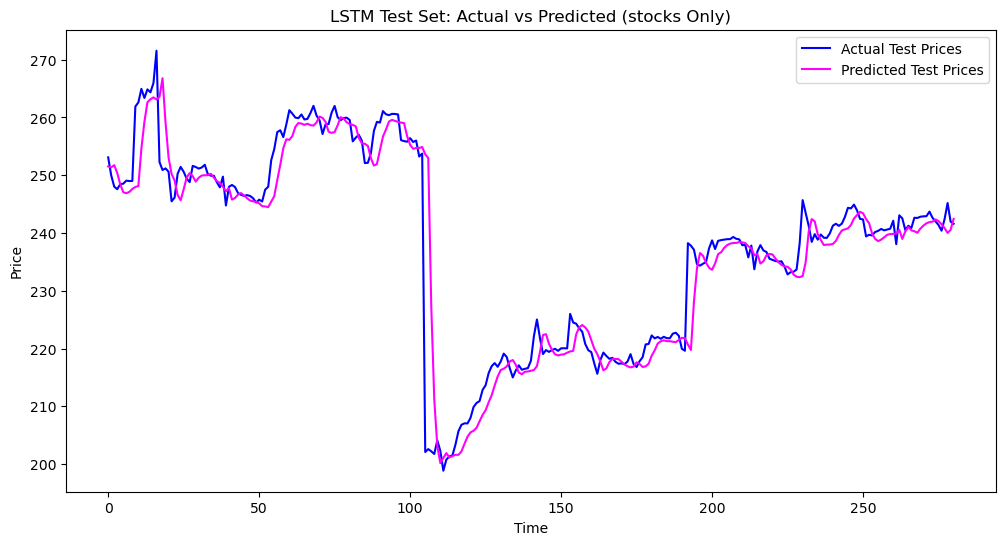

In [14]:

# calculate root mean squared error
trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

# get actual test prices
testPrices = scaler.inverse_transform(dataset[test_size + look_back:])
plt.figure(figsize=(12,6))

# plot actual vs predicted for test set
plt.plot(testPrices[-test_size:], label="Actual Test Prices", color="blue")
plt.plot(testPredict, label="Predicted Test Prices", color="magenta")
plt.legend()
plt.title("LSTM Test Set: Actual vs Predicted (stocks Only)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.show()
